# Video Violence Detection + Crowd Analytics

**Team:** Somaya Ossama · Jana Emad

1. **Violence classifier**: MobileNet (ImageNet, frozen) on each of 10 frames → Bi-LSTM over time → P(violence).
2. **Crowd analytics**: YOLOv8n counts people per frame → crowd density level (LOW / MEDIUM / HIGH).
3. **Fusion**: annotated output videos showing violence label, people count and density.

The dataset is not included. See the README.

In [1]:
import numpy as np
import cv2
import os
from tensorflow.keras.applications import MobileNet
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, TimeDistributed, Dropout, Bidirectional, GlobalAveragePooling2D
from sklearn.model_selection import train_test_split
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

import pandas as pd

# Download the Real Life Violence Situations dataset (see README) and point DATA_DIR at it.
DATA_DIR = 'Real Life Violence Dataset'   # contains NonViolence/ and Violence/
OUTPUT_DIR = 'outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)


## 1. Dataset: Real Life Violence Situations
951 non-violent + 1,000 violent clips.

In [2]:

# Path to your dataset folder
dataset_path = DATA_DIR
classes = ['NonViolence', 'Violence']
video_extensions = ('.mp4')  # accepted video formats

# Dictionary to store video counts
video_counts = {}

# Loop through each class folder
for cls in classes:
    cls_path = os.path.join(dataset_path, cls)
    if not os.path.exists(cls_path):
        print(f"Folder not found: {cls_path}")
        continue

    # List video files with valid extensions
    videos = [f for f in os.listdir(cls_path) if f.endswith(video_extensions)]
    video_counts[cls] = len(videos)

    print(f"Class '{cls}' has {len(videos)} video(s):")
    for vid in videos:
        print("  ", vid)

# Total videos
total_videos = sum(video_counts.values())
print(f"\nTotal videos in dataset: {total_videos}")


Class 'NonViolence' has 951 video(s):
   NV_1.mp4
   NV_10.mp4
   NV_100.mp4
   NV_1000.mp4
   NV_101.mp4
   NV_102.mp4
   NV_103.mp4
   NV_104.mp4
   NV_105.mp4
   NV_106.mp4
   NV_107.mp4
   NV_108.mp4
   NV_109.mp4
   NV_11.mp4
   NV_110.mp4
   NV_111.mp4
   NV_112.mp4
   NV_113.mp4
   NV_114.mp4
   NV_115.mp4
   NV_116.mp4
   NV_117.mp4
   NV_118.mp4
   NV_119.mp4
   NV_12.mp4
   NV_120.mp4
   NV_121.mp4
   NV_122.mp4
   NV_123.mp4
   NV_124.mp4
   NV_125.mp4
   NV_126.mp4
   NV_127.mp4
   NV_128.mp4
   NV_129.mp4
   NV_13.mp4
   NV_130.mp4
   NV_131.mp4
   NV_132.mp4
   NV_133.mp4
   NV_134.mp4
   NV_135.mp4
   NV_136.mp4
   NV_137.mp4
   NV_138.mp4
   NV_139.mp4
   NV_14.mp4
   NV_140.mp4
   NV_141.mp4
   NV_142.mp4
   NV_143.mp4
   NV_144.mp4
   NV_145.mp4
   NV_146.mp4
   NV_147.mp4
   NV_148.mp4
   NV_149.mp4
   NV_15.mp4
   NV_150.mp4
   NV_151.mp4
   NV_152.mp4
   NV_153.mp4
   NV_154.mp4
   NV_155.mp4
   NV_156.mp4
   NV_157.mp4
   NV_158.mp4
   NV_159.mp4
   NV_16.mp4
   N

In [3]:
video_path = os.path.join(DATA_DIR, 'Violence', 'V_143.mp4')


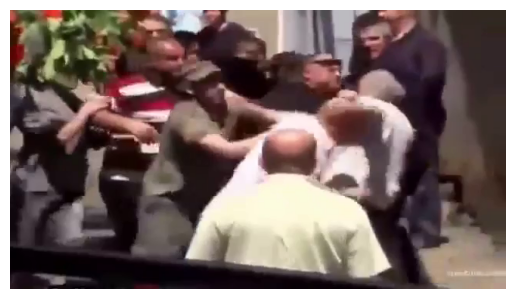

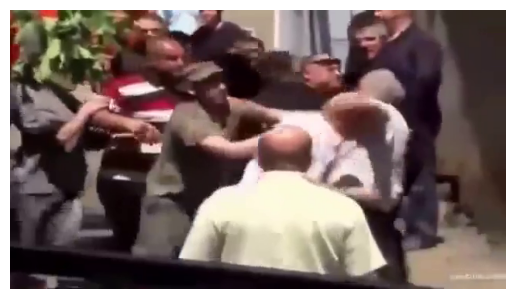

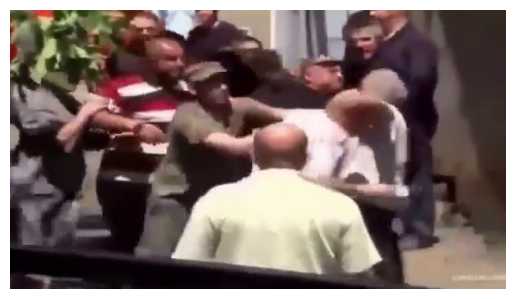

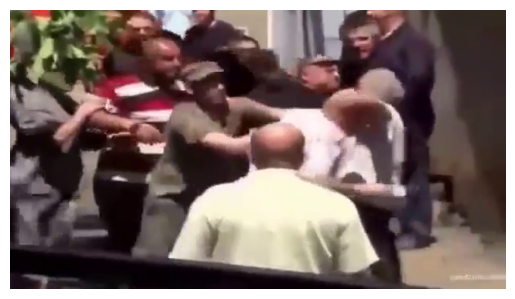

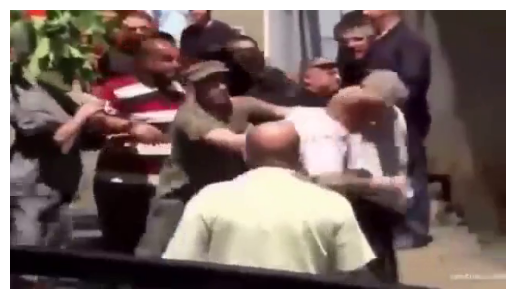

In [4]:
import matplotlib.pyplot as plt
cap = cv2.VideoCapture(video_path)
frame_count = 0

while True:
    ret, frame = cap.read()
    if not ret or frame_count >= 5:  # show only the first 5 frames
        break
    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)  # convert BGR -> RGB for matplotlib
    plt.imshow(frame)
    plt.axis('off')
    plt.show()
    frame_count += 1

cap.release()


In [5]:
dataset_path = DATA_DIR
classes = ['NonViolence', 'Violence']
video_extensions = ('.mp4')
max_frames = 10        # reduce to save memory
frame_size = (160, 160) # reduce size to save memory

## 2. Frame extraction
The first 10 frames of each clip, resized to 160×160 (padded with the last frame if the clip is shorter).

In [6]:
def extract_frames(video_path, max_frames=max_frames, resize=frame_size):
    cap = cv2.VideoCapture(video_path)
    frames = []
    count = 0

    while count < max_frames:
        ret, frame = cap.read()
        if not ret:
            break
        frame = cv2.resize(frame, resize)
        frames.append(frame)
        count += 1
    cap.release()

    # Pad with last frame if video is shorter
    while len(frames) < max_frames:
        frames.append(frames[-1])
    
    return np.array(frames)

In [7]:

X, y = [], []

for label, cls in enumerate(classes):
    cls_path = os.path.join(dataset_path, cls)
    if not os.path.exists(cls_path):
        print(f"Folder not found: {cls_path}")
        continue

    videos = [f for f in os.listdir(cls_path) if f.endswith(video_extensions)]
    print(f"Processing {len(videos)} videos from class '{cls}'")

    for video_file in videos:
        video_path = os.path.join(cls_path, video_file)
        frames = extract_frames(video_path)
        X.append(frames)
        y.append(label)

X = np.array(X)
y = np.array(y)

print("Dataset ready!")
print("X shape:", X.shape)  # (num_videos, 10, 160, 160, 3)
print("y shape:", y.shape)

Processing 951 videos from class 'NonViolence'
Processing 1000 videos from class 'Violence'
Dataset ready!
X shape: (1951, 10, 160, 160, 3)
y shape: (1951,)


## 3. Train / held-out split (80 / 20, stratified)

In [8]:
# Step 4: Train/Test split
# ======================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape, y_train.shape)
print("Testing set:", X_test.shape, y_test.shape)


Training set: (1560, 10, 160, 160, 3) (1560,)
Testing set: (391, 10, 160, 160, 3) (391,)


## 4. Model: MobileNet + Bi-LSTM

In [14]:
# Step 5: Build MobileNet + Bi-LSTM
# ======================
mobilenet = MobileNet(weights='imagenet', include_top=False, input_shape=(160, 160, 3))
mobilenet.trainable = False

cnn_model = Sequential([
    mobilenet,
    GlobalAveragePooling2D()
])

model = Sequential([
    TimeDistributed(cnn_model, input_shape=(max_frames, 160, 160, 3)),
    Bidirectional(LSTM(64)),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer=Adam(1e-4), loss='binary_crossentropy', metrics=['accuracy'])
model.summary()




Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ time_distributed_1              │ (None, 10, 1024)       │     3,228,864 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │       557,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,786,561 (14.44 MB)

 Trainable params: 557,697 (2.13 MB)

 Non-trainable params: 3,228,864 (12.32 MB)

## 5. Training
⚠️ The held-out 20% is passed as `validation_data`, so early stopping and checkpointing look at it. Accuracy on it is therefore slightly optimistic. See *Limitations* in the README.

In [15]:
early_stop = EarlyStopping(
    monitor='val_accuracy',
    patience=3,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    'best_model.h5',
    monitor='val_accuracy',
    save_best_only=True
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=5,
    batch_size=2,
    callbacks=[early_stop, checkpoint]
)


Epoch 1/5
780/780 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - accuracy: 0.6218 - loss: 0.6382

780/780 ━━━━━━━━━━━━━━━━━━━━ 204s 232ms/step - accuracy: 0.6218 - loss: 0.6382 - val_accuracy: 0.7417 - val_loss: 0.5120
Epoch 2/5
780/780 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - accuracy: 0.7504 - loss: 0.4966

780/780 ━━━━━━━━━━━━━━━━━━━━ 175s 224ms/step - accuracy: 0.7504 - loss: 0.4966 - val_accuracy: 0.7494 - val_loss: 0.4864
Epoch 3/5
780/780 ━━━━━━━━━━━━━━━━━━━━ 173s 222ms/step - accuracy: 0.7974 - loss: 0.4365 - val_accuracy: 0.7417 - val_loss: 0.4958
Epoch 4/5
780/780 ━━━━━━━━━━━━━━━━━━━━ 0s 622ms/step - accuracy: 0.7956 - loss: 0.4070

780/780 ━━━━━━━━━━━━━━━━━━━━ 526s 674ms/step - accuracy: 0.7956 - loss: 0.4070 - val_accuracy: 0.7775 - val_loss: 0.4422
Epoch 5/5
780/780 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step - accuracy: 0.8340 - loss: 0.3501

780/780 ━━━━━━━━━━━━━━━━━━━━ 335s 429ms/step - accuracy: 0.8340 - loss: 0.3502 - val_accuracy: 0.7826 - val_loss: 0.4702


In [ ]:
from tensorflow.keras.models import load_model

best_model = load_model('best_model.h5')



## 6. Predictions
This loop scores **all** 1,951 videos (training and held-out). The README's metrics use only the 391 held-out videos.

In [17]:
print("\nPredictions on dataset videos:")

for i, video_frames in enumerate(X):
    video_input = np.expand_dims(video_frames, axis=0)
    pred = best_model.predict(video_input, verbose=0)

    score = pred[0][0]
    label = "Violence" if score > 0.5 else "NonViolence"
    confidence = score if score > 0.5 else 1 - score

    print(f"Video {i+1}: {label} ({confidence:.2f})")



Predictions on dataset videos:
Video 1: NonViolence (0.96)
Video 2: NonViolence (0.96)
Video 3: NonViolence (0.79)
Video 4: NonViolence (0.86)
Video 5: NonViolence (0.92)
Video 6: NonViolence (0.86)
Video 7: NonViolence (0.99)
Video 8: NonViolence (0.61)
Video 9: NonViolence (0.78)
Video 10: NonViolence (0.99)
Video 11: NonViolence (0.97)
Video 12: NonViolence (0.70)
Video 13: NonViolence (0.96)
Video 14: NonViolence (0.85)
Video 15: NonViolence (0.92)
Video 16: NonViolence (0.97)
Video 17: NonViolence (0.98)
Video 18: NonViolence (0.97)
Video 19: NonViolence (0.98)
Video 20: NonViolence (0.98)
Video 21: NonViolence (0.87)
Video 22: NonViolence (0.64)
Video 23: NonViolence (0.75)
Video 24: NonViolence (0.88)
Video 25: Violence (0.66)
Video 26: NonViolence (0.78)
Video 27: NonViolence (0.98)
Video 28: Violence (0.53)
Video 29: NonViolence (0.93)
Video 30: NonViolence (0.97)
Video 31: NonViolence (0.98)
Video 32: NonViolence (0.97)
Video 33: NonViolence (0.64)
Video 34: NonViolence (0.9

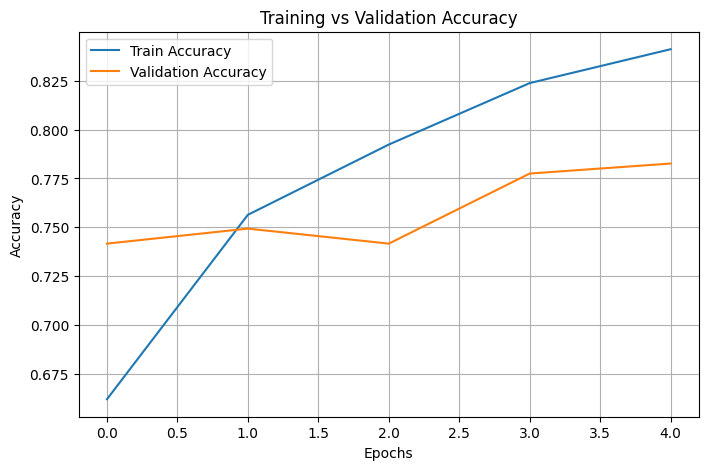

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()


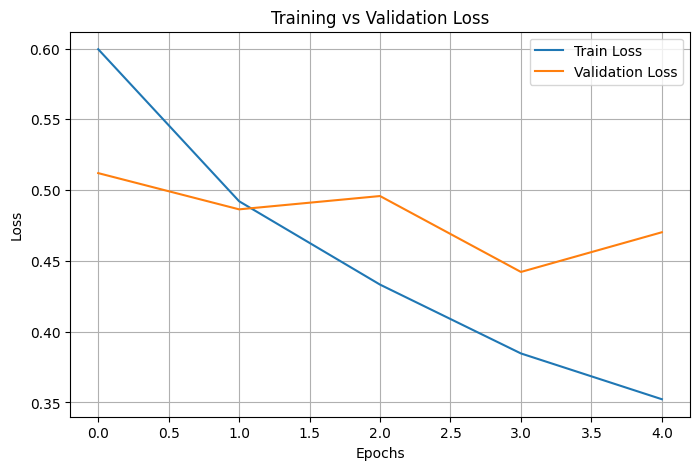

In [19]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.grid(True)
plt.show()


## 7. Crowd analytics with YOLOv8n
People per frame → density = people per 100k pixels → LOW (< 5), MEDIUM (5–15), HIGH (≥ 15).

In [21]:
from ultralytics import YOLO
import csv

In [22]:
# ===================== PATHS =====================
DATASET_DIR = DATA_DIR
OUTPUT_VIDEO_DIR = os.path.join(OUTPUT_DIR, 'crowd_videos')
RESULTS_DIR = OUTPUT_VIDEO_DIR
CSV_PATH = os.path.join(RESULTS_DIR, "crowd_density_features.csv")

SUPPORTED_EXTENSIONS = (".mp4")
MAX_VIDEOS_PER_CLASS = 100   # ✅ LIMIT HERE

# ===================== CREATE DIRS =====================
os.makedirs(OUTPUT_VIDEO_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

In [23]:
yolo = YOLO("yolov8n.pt")

In [24]:
csv_file = open(CSV_PATH, "w", newline="", encoding="utf-8")
csv_writer = csv.writer(csv_file)
csv_writer.writerow([
    "video_name",
    "label",
    "avg_people",
    "max_people",
    "avg_density",
    "max_density"
])


64

In [25]:
# ===================== PROCESS DATASET =====================
for label in os.listdir(DATASET_DIR):

    input_folder = os.path.join(DATASET_DIR, label)
    if not os.path.isdir(input_folder):
        continue

    print(f"\n📁 Processing class: {label}")

    output_folder = os.path.join(OUTPUT_VIDEO_DIR, label)
    os.makedirs(output_folder, exist_ok=True)

    # Get videos & limit to 100
    videos = [
        v for v in os.listdir(input_folder)
        if v.lower().endswith(SUPPORTED_EXTENSIONS)
    ][:MAX_VIDEOS_PER_CLASS]

    print(f"➡ Processing {len(videos)} videos (max {MAX_VIDEOS_PER_CLASS})")

    for video_name in videos:

        video_path = os.path.join(input_folder, video_name)
        print(f"🎥 {video_name}")

        cap = cv2.VideoCapture(video_path)
        if not cap.isOpened():
            print("❌ Cannot open video")
            continue

        width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        fps = int(cap.get(cv2.CAP_PROP_FPS))

        out_path = os.path.join(output_folder, video_name)
        out = cv2.VideoWriter(
            out_path,
            cv2.VideoWriter_fourcc(*"mp4v"),
            fps,
            (width, height)
        )

        # ===== Stats =====
        total_people = 0
        total_density = 0
        max_people = 0
        max_density = 0
        frames = 0

        # ===================== FRAME LOOP =====================
        while True:
            ret, frame = cap.read()
            if not ret:
                break

            results = yolo(frame, conf=0.4, verbose=False)[0]

            people = 0
            for box in results.boxes:
                cls_id = int(box.cls[0])
                if results.names[cls_id] == "person":
                    people += 1

            area = width * height
            density = (people / area) * 100000

            total_people += people
            total_density += density
            max_people = max(max_people, people)
            max_density = max(max_density, density)
            frames += 1

            # Density alert
            if density < 5:
                color = (0, 255, 0)
                text = "LOW DENSITY"
            elif density < 15:
                color = (0, 255, 255)
                text = "MEDIUM DENSITY"
            else:
                color = (0, 0, 255)
                text = "HIGH CROWD RISK"

            annotated = results.plot()
            cv2.rectangle(annotated, (10, 10), (width - 10, 70), color, -1)
            cv2.putText(
                annotated,
                f"{text} | People: {people}",
                (20, 55),
                cv2.FONT_HERSHEY_SIMPLEX,
                1.1,
                (255, 255, 255),
                3
            )

            out.write(annotated)

        cap.release()
        out.release()

        # ===== Save features =====
        avg_people = total_people / frames if frames else 0
        avg_density = total_density / frames if frames else 0

        csv_writer.writerow([
            video_name,
            label,
            round(avg_people, 2),
            max_people,
            round(avg_density, 2),
            round(max_density, 2)
        ])

        print("✅ Saved")

csv_file.close()
print("\n🎉 Crowd density completed (100 videos per class)")


📁 Processing class: NonViolence
➡ Processing 100 videos (max 100)
🎥 NV_1.mp4
✅ Saved
🎥 NV_10.mp4
✅ Saved
🎥 NV_100.mp4
✅ Saved
🎥 NV_1000.mp4
✅ Saved
🎥 NV_101.mp4
✅ Saved
🎥 NV_102.mp4
✅ Saved
🎥 NV_103.mp4
✅ Saved
🎥 NV_104.mp4
✅ Saved
🎥 NV_105.mp4
✅ Saved
🎥 NV_106.mp4
✅ Saved
🎥 NV_107.mp4
✅ Saved
🎥 NV_108.mp4
✅ Saved
🎥 NV_109.mp4
✅ Saved
🎥 NV_11.mp4
✅ Saved
🎥 NV_110.mp4
✅ Saved
🎥 NV_111.mp4
✅ Saved
🎥 NV_112.mp4
✅ Saved
🎥 NV_113.mp4
✅ Saved
🎥 NV_114.mp4
✅ Saved
🎥 NV_115.mp4
✅ Saved
🎥 NV_116.mp4
✅ Saved
🎥 NV_117.mp4
✅ Saved
🎥 NV_118.mp4
✅ Saved
🎥 NV_119.mp4
✅ Saved
🎥 NV_12.mp4
✅ Saved
🎥 NV_120.mp4
✅ Saved
🎥 NV_121.mp4
✅ Saved
🎥 NV_122.mp4
✅ Saved
🎥 NV_123.mp4
✅ Saved
🎥 NV_124.mp4
✅ Saved
🎥 NV_125.mp4
✅ Saved
🎥 NV_126.mp4
✅ Saved
🎥 NV_127.mp4
✅ Saved
🎥 NV_128.mp4
✅ Saved
🎥 NV_129.mp4
✅ Saved
🎥 NV_13.mp4
✅ Saved
🎥 NV_130.mp4
✅ Saved
🎥 NV_131.mp4
✅ Saved
🎥 NV_132.mp4
✅ Saved
🎥 NV_133.mp4
✅ Saved
🎥 NV_134.mp4
✅ Saved
🎥 NV_135.mp4
✅ Saved
🎥 NV_136.mp4
✅ Saved
🎥 NV_137.mp4
✅ Saved
🎥 NV_138.mp4
✅

In [ ]:

# Paths
DATASET_DIR = DATA_DIR
OUTPUT_CSV = os.path.join(OUTPUT_DIR, 'violence_predictions.csv')

# Load your trained model
model = load_model("best_model.h5")

# Video settings
MAX_FRAMES = 10
FRAME_SIZE = (160, 160)  # same as used in training
SUPPORTED_EXTENSIONS = (".mp4")


## 8. Fusion: violence + crowd overlay on the video

In [32]:
def predict_video_violence(video_path, max_frames=MAX_FRAMES, frame_size=FRAME_SIZE):
    cap = cv2.VideoCapture(video_path)
    frames = []

    while len(frames) < max_frames:
        ret, frame = cap.read()
        if not ret:
            break
        frame = cv2.resize(frame, frame_size)
        frames.append(frame)

    cap.release()

    if len(frames) == 0:
        return 0.0  # default to non-violence

    # Pad frames if shorter than max_frames
    while len(frames) < max_frames:
        frames.append(frames[-1])

    frames = np.array(frames)
    frames = np.expand_dims(frames, axis=0)  # shape (1, max_frames, h, w, 3)

    score = model.predict(frames, verbose=0)[0][0]
    return float(score)


In [33]:
predictions = []

for cls in os.listdir(DATASET_DIR):
    cls_path = os.path.join(DATASET_DIR, cls)
    if not os.path.isdir(cls_path):
        continue

    # Limit to 50 videos per class if needed
    videos = [v for v in os.listdir(cls_path) if v.lower().endswith(SUPPORTED_EXTENSIONS)][:50]

    for video_name in videos:
        video_path = os.path.join(cls_path, video_name)
        print(f"Processing {video_name} ...")

        score = predict_video_violence(video_path)
        predictions.append({
            "video_name": video_name,
            "label": cls,
            "violence_prob": score
        })

# Save to CSV
df = pd.DataFrame(predictions)
df.to_csv(OUTPUT_CSV, index=False)
print(f"\n✅ Violence predictions saved to {OUTPUT_CSV}")


Processing NV_1.mp4 ...
Processing NV_10.mp4 ...
Processing NV_100.mp4 ...
Processing NV_1000.mp4 ...
Processing NV_101.mp4 ...
Processing NV_102.mp4 ...
Processing NV_103.mp4 ...
Processing NV_104.mp4 ...
Processing NV_105.mp4 ...
Processing NV_106.mp4 ...
Processing NV_107.mp4 ...
Processing NV_108.mp4 ...
Processing NV_109.mp4 ...
Processing NV_11.mp4 ...
Processing NV_110.mp4 ...
Processing NV_111.mp4 ...
Processing NV_112.mp4 ...
Processing NV_113.mp4 ...
Processing NV_114.mp4 ...
Processing NV_115.mp4 ...
Processing NV_116.mp4 ...
Processing NV_117.mp4 ...
Processing NV_118.mp4 ...
Processing NV_119.mp4 ...
Processing NV_12.mp4 ...
Processing NV_120.mp4 ...
Processing NV_121.mp4 ...
Processing NV_122.mp4 ...
Processing NV_123.mp4 ...
Processing NV_124.mp4 ...
Processing NV_125.mp4 ...
Processing NV_126.mp4 ...
Processing NV_127.mp4 ...
Processing NV_128.mp4 ...
Processing NV_129.mp4 ...
Processing NV_13.mp4 ...
Processing NV_130.mp4 ...
Processing NV_131.mp4 ...
Processing NV_132

In [36]:

import pandas as pd

# ===================== PATHS =====================
DATASET_DIR = DATA_DIR
VIOLENCE_CSV = os.path.join(OUTPUT_DIR, 'violence_predictions.csv')
FUSION_DIR = os.path.join(OUTPUT_DIR, 'final_fusion_videos')

SUPPORTED_EXTENSIONS = (".mp4")
MAX_VIDEOS_PER_CLASS = 50  #  reduced to 50 videos per class
TARGET_WIDTH, TARGET_HEIGHT = 640, 360  # optional resize to save memory

# ===================== LOAD =====================
yolo = YOLO("yolov8n.pt")
violence_df = pd.read_csv(VIOLENCE_CSV)
os.makedirs(FUSION_DIR, exist_ok=True)

# ===================== PROCESS =====================
for label in os.listdir(DATASET_DIR):
    input_folder = os.path.join(DATASET_DIR, label)
    if not os.path.isdir(input_folder):
        continue

    output_folder = os.path.join(FUSION_DIR, label)
    os.makedirs(output_folder, exist_ok=True)

    videos = [
        v for v in os.listdir(input_folder)
        if v.lower().endswith(SUPPORTED_EXTENSIONS)
    ][:MAX_VIDEOS_PER_CLASS]

    print(f"\n {label}: processing {len(videos)} videos")

    for video_name in videos:
        video_path = os.path.join(input_folder, video_name)

        # ===== Violence label =====
        row = violence_df[violence_df["video_name"] == video_name]
        if row.empty:
            print(f"⚠ Missing violence prediction for {video_name}")
            continue

        violence_prob = float(row["violence_prob"].values[0])
        violence_label = "VIOLENT" if violence_prob >= 0.5 else "NON-VIOLENT"

        cap = cv2.VideoCapture(video_path)
        if not cap.isOpened():
            print(f" Cannot open {video_name}")
            continue

        # Optional resize
        width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        fps = int(cap.get(cv2.CAP_PROP_FPS))
        scale_x = TARGET_WIDTH / width
        scale_y = TARGET_HEIGHT / height

        out_path = os.path.join(output_folder, video_name)
        out = cv2.VideoWriter(
            out_path,
            cv2.VideoWriter_fourcc(*"mp4v"),
            fps,
            (TARGET_WIDTH, TARGET_HEIGHT)
        )

        # ===================== FRAME LOOP =====================
        while True:
            ret, frame = cap.read()
            if not ret:
                break

            # Resize frame if needed
            frame = cv2.resize(frame, (TARGET_WIDTH, TARGET_HEIGHT))

            results = yolo(frame, conf=0.4, verbose=False)[0]

            # ===== People count =====
            people = sum(
                1 for box in results.boxes
                if results.names[int(box.cls[0])] == "person"
            )

            # ===== Crowd density =====
            area = TARGET_WIDTH * TARGET_HEIGHT
            density_score = (people / area) * 100000
            if density_score < 5:
                density_label = "LOW"
                color = (0, 255, 0)
            elif density_score < 15:
                density_label = "MEDIUM"
                color = (0, 255, 255)
            else:
                density_label = "HIGH"
                color = (0, 0, 255)

            annotated = results.plot()

            # ===== Overlay crowd info (bottom) =====
            cv2.putText(annotated, f"People Count: {people}", 
                        (20, TARGET_HEIGHT-80), cv2.FONT_HERSHEY_SIMPLEX, 1, (255,255,255), 2)
            cv2.putText(annotated, f"Crowd Density: {density_label}", 
                        (20, TARGET_HEIGHT-40), cv2.FONT_HERSHEY_SIMPLEX, 1, (255,255,255), 2)

            # ===== Overlay violence info (top) =====
            cv2.putText(annotated, f"Violence: {violence_label}", 
                        (20, 50), cv2.FONT_HERSHEY_SIMPLEX, 1, (0,0,255), 3)

            out.write(annotated)

        cap.release()
        out.release()
        print(f" Saved: {video_name}")

print("\n Annotated fusion videos completed (50 per class)")



 NonViolence: processing 50 videos
 Saved: NV_1.mp4
 Saved: NV_10.mp4
 Saved: NV_100.mp4
 Saved: NV_1000.mp4
 Saved: NV_101.mp4
 Saved: NV_102.mp4
 Saved: NV_103.mp4
 Saved: NV_104.mp4
 Saved: NV_105.mp4
 Saved: NV_106.mp4
 Saved: NV_107.mp4
 Saved: NV_108.mp4
 Saved: NV_109.mp4
 Saved: NV_11.mp4
 Saved: NV_110.mp4
 Saved: NV_111.mp4
 Saved: NV_112.mp4
 Saved: NV_113.mp4
 Saved: NV_114.mp4
 Saved: NV_115.mp4
 Saved: NV_116.mp4
 Saved: NV_117.mp4
 Saved: NV_118.mp4
 Saved: NV_119.mp4
 Saved: NV_12.mp4
 Saved: NV_120.mp4
 Saved: NV_121.mp4
 Saved: NV_122.mp4
 Saved: NV_123.mp4
 Saved: NV_124.mp4
 Saved: NV_125.mp4
 Saved: NV_126.mp4
 Saved: NV_127.mp4
 Saved: NV_128.mp4
 Saved: NV_129.mp4
 Saved: NV_13.mp4
 Saved: NV_130.mp4
 Saved: NV_131.mp4
 Saved: NV_132.mp4
 Saved: NV_133.mp4
 Saved: NV_134.mp4
 Saved: NV_135.mp4
 Saved: NV_136.mp4
 Saved: NV_137.mp4
 Saved: NV_138.mp4
 Saved: NV_139.mp4
 Saved: NV_14.mp4
 Saved: NV_140.mp4
 Saved: NV_141.mp4
 Saved: NV_142.mp4

 Violence: processi

## 9. Held-out evaluation
Confusion matrix on the 391 held-out videos only. The README reports the result (79.3% accuracy) and the alert-threshold trade-off.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

p_test = best_model.predict(X_test, batch_size=4, verbose=0).ravel()
print(confusion_matrix(y_test, p_test > 0.5))
print(classification_report(y_test, p_test > 0.5, target_names=classes, digits=3))